In [6]:
import pandas as pd

awards = pd.read_csv("data/Player Award Shares.csv")
stats = pd.read_csv("data/Player Per Game.csv")

print("Awards shape:", awards.shape)
print("Stats shape:", stats.shape)

Awards shape: (3465, 10)
Stats shape: (33339, 32)


In [7]:
print("AWARDS COLUMNS:")
print(awards.columns.tolist())

print("\nSTATS COLUMNS:")
print(stats.columns.tolist())

AWARDS COLUMNS:
['season', 'award', 'player', 'player_id', 'age', 'first', 'pts_won', 'pts_max', 'share', 'winner']

STATS COLUMNS:
['season', 'lg', 'player', 'player_id', 'age', 'team', 'pos', 'g', 'gs', 'mp_per_game', 'fg_per_game', 'fga_per_game', 'fg_percent', 'x3p_per_game', 'x3pa_per_game', 'x3p_percent', 'x2p_per_game', 'x2pa_per_game', 'x2p_percent', 'e_fg_percent', 'ft_per_game', 'fta_per_game', 'ft_percent', 'orb_per_game', 'drb_per_game', 'trb_per_game', 'ast_per_game', 'stl_per_game', 'blk_per_game', 'tov_per_game', 'pf_per_game', 'pts_per_game']


In [8]:
mvp = awards[awards["award"] == "nba_mvp"]

print("MVP records:", len(mvp))
print("MVP winners:", mvp["winner"].sum())
print("Seasons:", mvp["season"].nunique())

MVP records: 0
MVP winners: 0
Seasons: 0


In [9]:
print(awards["award"].unique())

<ArrowStringArray>
['nba clutch_poy',       'nba dpoy',        'nba mip',        'nba mvp',
        'nba roy',       'nba smoy',        'aba mvp',        'aba roy',
        'baa roy']
Length: 9, dtype: str


In [10]:
mvp = awards[awards["award"] == "nba mvp"]

print("MVP records:", len(mvp))
print("MVP winners:", mvp["winner"].sum())
print("Seasons:", mvp["season"].nunique())

MVP records: 1057
MVP winners: 70
Seasons: 70


In [11]:
print(mvp["season"].min())
print(mvp["season"].max())

1956
2025


In [12]:
print(mvp["winner"].dtype)
print(mvp["winner"].value_counts())

bool
winner
False    987
True      70
Name: count, dtype: int64


In [13]:
print(mvp[mvp["winner"] == True][["season", "player", "pts_won", "share"]].head(10))

     season                   player  pts_won  share
39     2025  Shai Gilgeous-Alexander    913.0  0.913
109    2024             Nikola Jokić    926.0  0.935
175    2023              Joel Embiid    915.0  0.915
227    2022             Nikola Jokić    875.0  0.875
295    2021             Nikola Jokić    971.0  0.961
356    2020    Giannis Antetokounmpo    962.0  0.952
417    2019    Giannis Antetokounmpo    941.0  0.932
501    2018             James Harden    965.0  0.955
570    2017        Russell Westbrook    888.0  0.879
641    2016            Stephen Curry   1310.0  1.000


In [14]:
duplicates = stats.duplicated(subset=["season", "player_id"], keep=False)

print("Duplicate player-season rows:", duplicates.sum())

Duplicate player-season rows: 9459


In [15]:
print(stats[stats["team"] == "TOT"].head())

Empty DataFrame
Columns: [season, lg, player, player_id, age, team, pos, g, gs, mp_per_game, fg_per_game, fga_per_game, fg_percent, x3p_per_game, x3pa_per_game, x3p_percent, x2p_per_game, x2pa_per_game, x2p_percent, e_fg_percent, ft_per_game, fta_per_game, ft_percent, orb_per_game, drb_per_game, trb_per_game, ast_per_game, stl_per_game, blk_per_game, tov_per_game, pf_per_game, pts_per_game]
Index: []

[0 rows x 32 columns]


In [16]:
duplicate_rows = stats[stats.duplicated(
    subset=["season", "player_id"],
    keep=False
)]

print(duplicate_rows[[
    "season", "player", "team", "g",
    "fg_per_game", "fga_per_game",
    "trb_per_game", "ast_per_game", "pts_per_game"
]].head(10))

    season         player team   g  fg_per_game  fga_per_game  trb_per_game  \
3     2026   Ochai Agbaji  2TM  62          2.0           4.5           2.3   
4     2026   Ochai Agbaji  TOR  42          1.7           4.0           2.3   
5     2026   Ochai Agbaji  BRK  20          2.5           5.5           2.3   
11    2026  Jose Alvarado  2TM  69          2.7           6.5           2.5   
12    2026  Jose Alvarado  NOP  41          2.9           6.8           2.8   
13    2026  Jose Alvarado  NYK  28          2.5           6.0           2.0   
14    2026  Kyle Anderson  3TM  43          2.5           4.7           3.5   
15    2026  Kyle Anderson  UTA  20          2.9           5.5           3.3   
16    2026  Kyle Anderson  MEM   4          3.8           4.8           3.5   
17    2026  Kyle Anderson  MIN  19          1.8           3.9           3.7   

    ast_per_game  pts_per_game  
3            0.8           5.1  
4            0.7           4.3  
5            0.9           6.7 

In [17]:
print(stats[stats["team"].str.contains("TM", na=False)]["team"].value_counts())

team
2TM    2838
3TM     205
4TM       8
5TM       1
Name: count, dtype: int64


In [18]:
tm_rows = stats[stats["team"].str.contains("TM", na=False)]

print("Combined-team rows:", len(tm_rows))
print("Single-team rows:", len(stats[~stats["player_id"].isin(tm_rows["player_id"]) ]))

Combined-team rows: 3052
Single-team rows: 11864


In [19]:
tm_mask = stats["team"].str.contains("TM", na=False)

clean_stats = stats[
    tm_mask | ~stats.duplicated(subset=["season", "player_id"], keep=False)
].copy()

print("Original rows:", len(stats))
print("Clean rows:", len(clean_stats))
print("Duplicate player-seasons remaining:",
      clean_stats.duplicated(subset=["season", "player_id"]).sum())

Original rows: 33339
Clean rows: 26932
Duplicate player-seasons remaining: 0


In [20]:
print("Stats seasons:", clean_stats["season"].min(), "to", clean_stats["season"].max())
print("MVP seasons:", mvp["season"].min(), "to", mvp["season"].max())

Stats seasons: 1947 to 2026
MVP seasons: 1956 to 2025


In [21]:
clean_stats = clean_stats[
    (clean_stats["season"] >= 1956) &
    (clean_stats["season"] <= 2025)
].copy()

print("Clean stats shape:", clean_stats.shape)
print("Seasons:", clean_stats["season"].min(), "to", clean_stats["season"].max())

Clean stats shape: (25103, 32)
Seasons: 1956 to 2025


In [22]:
mvp_winners = mvp[mvp["winner"] == True][["season", "player_id"]].copy()

mvp_winners["mvp"] = 1

data = clean_stats.merge(
    mvp_winners,
    on=["season", "player_id"],
    how="left"
)

data["mvp"] = data["mvp"].fillna(0).astype(int)

print("Final dataset shape:", data.shape)
print(data["mvp"].value_counts())

Final dataset shape: (25103, 33)
mvp
0    25033
1       70
Name: count, dtype: int64


In [23]:
players_per_season = data.groupby("season")["player_id"].nunique()

print(players_per_season.describe())

count     70.000000
mean     358.614286
std      139.161911
min       92.000000
25%      306.000000
50%      383.500000
75%      451.750000
max      605.000000
Name: player_id, dtype: float64


In [24]:
print(data.groupby("season")["pts_per_game"].max().describe())

count    70.000000
mean     31.960000
std       3.896762
min      25.600000
25%      29.850000
50%      31.150000
75%      33.575000
max      50.400000
Name: pts_per_game, dtype: float64


In [25]:
mvp_sorted = mvp.sort_values(
    ["season", "pts_won"],
    ascending=[True, False]
)

print(mvp_sorted[[
    "season", "player", "pts_won", "winner"
]].tail(15))

     season                   player  pts_won  winner
115    2024          Anthony Edwards     18.0   False
116    2024         Domantas Sabonis      3.0   False
117    2024             Kevin Durant      1.0   False
39     2025  Shai Gilgeous-Alexander    913.0    True
40     2025             Nikola Jokić    787.0   False
41     2025    Giannis Antetokounmpo    470.0   False
42     2025             Jayson Tatum    311.0   False
43     2025         Donovan Mitchell     74.0   False
44     2025             LeBron James     16.0   False
45     2025          Cade Cunningham     12.0   False
46     2025          Anthony Edwards     12.0   False
47     2025            Stephen Curry      2.0   False
48     2025            Jalen Brunson      1.0   False
49     2025             James Harden      1.0   False
50     2025              Evan Mobley      1.0   False


In [26]:
for threshold in [50, 55, 60, 65]:
    count = (data["g"] >= threshold).groupby(data["season"]).sum()
    print(f"G >= {threshold}: average candidates =", round(count.mean(), 1))

G >= 50: average candidates = 232.3
G >= 55: average candidates = 214.8
G >= 60: average candidates = 195.2
G >= 65: average candidates = 172.6


In [27]:
eligible = data[data["g"] >= 50].copy()

print("Eligible rows:", len(eligible))
print("MVP winners:", eligible["mvp"].sum())

Eligible rows: 16264
MVP winners: 69


In [28]:
print(data[(data["mvp"] == 1) & (data["g"] < 50)][
    ["season", "player", "g"]
])

       season       player   g
12897    1999  Karl Malone  49


In [29]:
features = [
    "g",
    "mp_per_game",
    "fg_percent",
    "x3p_percent",
    "ft_percent",
    "trb_per_game",
    "ast_per_game",
    "stl_per_game",
    "blk_per_game",
    "pts_per_game"
]

X = data[features]
y = data["mvp"]

print("Features:", features)
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['g', 'mp_per_game', 'fg_percent', 'x3p_percent', 'ft_percent', 'trb_per_game', 'ast_per_game', 'stl_per_game', 'blk_per_game', 'pts_per_game']
X shape: (25103, 10)
y shape: (25103,)


In [30]:
train = data[data["season"] <= 2019].copy()
test = data[data["season"] >= 2020].copy()

X_train = train[features]
y_train = train["mvp"]

X_test = test[features]
y_test = test["mvp"]

print("Training:", X_train.shape, y_train.sum())
print("Testing:", X_test.shape, y_test.sum())

Training: (21749, 10) 64
Testing: (3354, 10) 6


In [31]:
print("Training missing values:")
print(X_train.isna().sum())

print("\nTesting missing values:")
print(X_test.isna().sum())

Training missing values:
g                  0
mp_per_game        0
fg_percent        63
x3p_percent     6785
ft_percent       587
trb_per_game       0
ast_per_game       0
stl_per_game    3202
blk_per_game    3200
pts_per_game       0
dtype: int64

Testing missing values:
g                 0
mp_per_game       0
fg_percent       21
x3p_percent     166
ft_percent      183
trb_per_game      0
ast_per_game      0
stl_per_game      0
blk_per_game      0
pts_per_game      0
dtype: int64


In [32]:
print(
    data.loc[data["x3p_percent"].isna(), "season"]
    .value_counts()
    .sort_index()
)

season
1956    92
1957    99
1958    99
1959    92
1960    99
        ..
2021    19
2022    44
2023    16
2024    32
2025    28
Name: count, Length: 70, dtype: int64


In [33]:
missing_by_season = data.groupby("season")[features].apply(lambda x: x.isna().sum().sum())

print(missing_by_season[missing_by_season > 0])

season
1956    276
1957    299
1958    300
1959    279
1960    299
       ... 
2021     38
2022    112
2023     42
2024     71
2025     53
Length: 70, dtype: int64


In [34]:
print(data.groupby("season")[features].apply(lambda x: x.isna().sum()).head(30))

        g  mp_per_game  fg_percent  x3p_percent  ft_percent  trb_per_game  \
season                                                                      
1956    0            0           0           92           0             0   
1957    0            0           0           99           2             0   
1958    0            0           0           99           3             0   
1959    0            0           0           92           3             0   
1960    0            0           0           99           2             0   
1961    0            0           0           93           0             0   
1962    0            0           0          113           3             0   
1963    0            0           0          117           1             0   
1964    0            0           0          111           3             0   
1965    0            0           0          114           1             0   
1966    0            0           0          111           3             0   

In [35]:
print("Training rows with any missing value:",
      X_train.isna().any(axis=1).sum())

print("Testing rows with any missing value:",
      X_test.isna().any(axis=1).sum())

Training rows with any missing value: 7669
Testing rows with any missing value: 302


In [36]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Training shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)
print("Missing values after imputation:", X_train_imputed.shape[0] - X_train_imputed.shape[0])

Training shape: (21749, 10)
Testing shape: (3354, 10)
Missing values after imputation: 0


In [37]:
print("Training missing:", pd.isna(X_train_imputed).sum())
print("Testing missing:", pd.isna(X_test_imputed).sum())

Training missing: 0
Testing missing: 0


In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)

Training: (21749, 10)
Testing: (3354, 10)


In [39]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logreg.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [40]:
y_pred = logreg.predict(X_test_scaled)
y_prob = logreg.predict_proba(X_test_scaled)[:, 1]

print("Predictions made:", len(y_pred))
print("Predicted MVPs:", y_pred.sum())

Predictions made: 3354
Predicted MVPs: 186


In [41]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     0.946     0.972      3348
           1      0.032     1.000     0.062         6

    accuracy                          0.946      3354
   macro avg      0.516     0.973     0.517      3354
weighted avg      0.998     0.946     0.971      3354



In [42]:
test_results = test[["season", "player", "player_id", "mvp"]].copy()

test_results["mvp_probability"] = y_prob

predicted_mvp = (
    test_results
    .sort_values(["season", "mvp_probability"], ascending=[True, False])
    .groupby("season")
    .first()
    .reset_index()
)

print(predicted_mvp[["season", "player", "mvp_probability", "mvp"]].to_string(index=False))

 season            player  mvp_probability  mvp
   2020       Luka Dončić         0.999923    0
   2021 Russell Westbrook         0.999921    0
   2022      Nikola Jokić         0.999981    1
   2023      Nikola Jokić         0.999925    0
   2024       Luka Dončić         0.999996    0
   2025      Nikola Jokić         0.999997    0


In [43]:
season_accuracy = predicted_mvp["mvp"].mean()

print(f"Season-level MVP accuracy: {season_accuracy:.3f}")

Season-level MVP accuracy: 0.167


In [44]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()

nb.fit(X_train_imputed, y_train)

print("Naive Bayes trained successfully.")

Naive Bayes trained successfully.


In [45]:
y_pred_nb = nb.predict(X_test_imputed)
y_prob_nb = nb.predict_proba(X_test_imputed)[:, 1]

print("Predictions made:", len(y_pred_nb))
print("Predicted MVPs:", y_pred_nb.sum())

Predictions made: 3354
Predicted MVPs: 99


In [46]:
test_results_nb = test[["season", "player", "player_id", "mvp"]].copy()

test_results_nb["mvp_probability"] = y_prob_nb

predicted_mvp_nb = (
    test_results_nb
    .sort_values(["season", "mvp_probability"], ascending=[True, False])
    .groupby("season")
    .first()
    .reset_index()
)

print(
    predicted_mvp_nb[
        ["season", "player", "mvp_probability", "mvp"]
    ].to_string(index=False)
)

 season            player  mvp_probability  mvp
   2020      James Harden         0.999910    0
   2021 Russell Westbrook         0.999988    0
   2022      Nikola Jokić         0.999996    1
   2023      Nikola Jokić         0.999927    0
   2024 Victor Wembanyama         1.000000    0
   2025      Nikola Jokić         1.000000    0


In [47]:
mvp = awards[awards["award"] == "nba_mvp"]

print("MVP records:", len(mvp))
print("MVP winners:", mvp["winner"].sum())
print("Seasons:", mvp["season"].nunique())

MVP records: 0
MVP winners: 0
Seasons: 0


In [48]:
mvp = awards[awards["award"] == "nba mvp"]

print("MVP records:", len(mvp))
print("MVP winners:", mvp["winner"].sum())
print("Seasons:", mvp["season"].nunique())

MVP records: 1057
MVP winners: 70
Seasons: 70


In [49]:
season_accuracy_nb = predicted_mvp_nb["mvp"].mean()

print(f"Naive Bayes season-level accuracy: {season_accuracy_nb:.3f}")

Naive Bayes season-level accuracy: 0.167


In [50]:
feature_importance = pd.DataFrame({
    "feature": features,
    "coefficient": logreg.coef_[0]
})

feature_importance["abs_coefficient"] = feature_importance["coefficient"].abs()

print(
    feature_importance
    .sort_values("abs_coefficient", ascending=False)
    .to_string(index=False)
)

     feature  coefficient  abs_coefficient
pts_per_game     3.309153         3.309153
 mp_per_game    -2.257536         2.257536
trb_per_game     2.205039         2.205039
ast_per_game     1.868591         1.868591
  ft_percent     0.924724         0.924724
           g     0.583251         0.583251
  fg_percent    -0.571281         0.571281
 x3p_percent    -0.125452         0.125452
blk_per_game     0.025146         0.025146
stl_per_game    -0.005039         0.005039


In [51]:
top5_logreg = (
    test_results
    .sort_values(["season", "mvp_probability"], ascending=[True, False])
    .groupby("season")
    .head(5)
)

print(
    top5_logreg[
        ["season", "player", "mvp_probability", "mvp"]
    ].to_string(index=False)
)

 season                  player  mvp_probability  mvp
   2020             Luka Dončić         0.999923    0
   2020            James Harden         0.999912    0
   2020   Giannis Antetokounmpo         0.999888    1
   2020            LeBron James         0.999179    0
   2020              Trae Young         0.999094    0
   2021       Russell Westbrook         0.999921    0
   2021            Nikola Jokić         0.999855    1
   2021            James Harden         0.999588    0
   2021             Luka Dončić         0.999316    0
   2021   Giannis Antetokounmpo         0.998268    0
   2022            Nikola Jokić         0.999981    1
   2022             Luka Dončić         0.999809    0
   2022   Giannis Antetokounmpo         0.999725    0
   2022             Joel Embiid         0.999580    0
   2022              Trae Young         0.999019    0
   2023            Nikola Jokić         0.999925    0
   2023             Luka Dončić         0.999896    0
   2023   Giannis Antetokoun

In [52]:
top3_logreg = (
    test_results
    .sort_values(["season", "mvp_probability"], ascending=[True, False])
    .groupby("season")
    .head(3)
)

top3_accuracy = (
    top3_logreg.groupby("season")["mvp"].max().mean()
)

print(f"Logistic Regression Top-3 accuracy: {top3_accuracy:.3f}")

Logistic Regression Top-3 accuracy: 0.667


In [53]:
top3_nb = (
    test_results_nb
    .sort_values(["season", "mvp_probability"], ascending=[True, False])
    .groupby("season")
    .head(3)
)

top3_accuracy_nb = (
    top3_nb.groupby("season")["mvp"].max().mean()
)

print(f"Naive Bayes Top-3 accuracy: {top3_accuracy_nb:.3f}")

Naive Bayes Top-3 accuracy: 0.667


In [54]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_imputed, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [55]:
y_pred_rf = rf.predict(X_test_imputed)
y_prob_rf = rf.predict_proba(X_test_imputed)[:, 1]

print("Predictions made:", len(y_pred_rf))
print("Predicted MVPs:", y_pred_rf.sum())

Predictions made: 3354
Predicted MVPs: 0


In [56]:
test_results_rf = test[["season", "player", "player_id", "mvp"]].copy()

test_results_rf["mvp_probability"] = y_prob_rf

predicted_mvp_rf = (
    test_results_rf
    .sort_values(["season", "mvp_probability"], ascending=[True, False])
    .groupby("season")
    .first()
    .reset_index()
)

print(
    predicted_mvp_rf[
        ["season", "player", "mvp_probability", "mvp"]
    ].to_string(index=False)
)

 season                  player  mvp_probability  mvp
   2020   Giannis Antetokounmpo         0.090000    1
   2021            Nikola Jokić         0.230000    1
   2022            Nikola Jokić         0.260000    1
   2023             Luka Dončić         0.120000    0
   2024 Shai Gilgeous-Alexander         0.306667    0
   2025            Nikola Jokić         0.183333    0


In [57]:
top3_rf = (
    test_results_rf
    .sort_values(["season", "mvp_probability"], ascending=[True, False])
    .groupby("season")
    .head(3)
)

top3_accuracy_rf = (
    top3_rf.groupby("season")["mvp"].max().mean()
)

print(f"Random Forest Top-3 accuracy: {top3_accuracy_rf:.3f}")

Random Forest Top-3 accuracy: 0.833


In [58]:
print(
    top3_rf.groupby("season")["mvp"].max()
)

season
2020    1
2021    1
2022    1
2023    0
2024    1
2025    1
Name: mvp, dtype: int32


In [59]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf, digits=3))

              precision    recall  f1-score   support

           0      0.998     1.000     0.999      3348
           1      0.000     0.000     0.000         6

    accuracy                          0.998      3354
   macro avg      0.499     0.500     0.500      3354
weighted avg      0.996     0.998     0.997      3354



c:\Users\rishi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\rishi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\rishi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

In [60]:
rf_importance = pd.DataFrame({
    "feature": features,
    "importance": rf.feature_importances_
})

print(
    rf_importance
    .sort_values("importance", ascending=False)
    .to_string(index=False)
)

     feature  importance
pts_per_game    0.295326
 mp_per_game    0.268339
trb_per_game    0.153110
ast_per_game    0.135359
           g    0.039198
  fg_percent    0.030931
stl_per_game    0.025326
  ft_percent    0.023663
blk_per_game    0.017012
 x3p_percent    0.011736


In [61]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Random Forest"
    ],
    "Top-1 Accuracy": [
        0.167,
        0.167,
        0.500
    ],
    "Top-3 Accuracy": [
        0.667,
        0.667,
        0.833
    ]
})

print(comparison.to_string(index=False))

              Model  Top-1 Accuracy  Top-3 Accuracy
Logistic Regression           0.167           0.667
        Naive Bayes           0.167           0.667
      Random Forest           0.500           0.833


In [62]:
def get_actual_mvp_rank(results):
    ranks = []

    for season in sorted(results["season"].unique()):
        season_data = results[results["season"] == season].sort_values(
            "score", ascending=False
        ).reset_index(drop=True)

        actual = season_data[season_data["mvp"] == 1]

        if len(actual) > 0:
            rank = actual.index[0] + 1
            ranks.append([season, actual.iloc[0]["player"], rank])

    return pd.DataFrame(ranks, columns=["season", "actual_mvp", "rank"])


logreg_rank = test_results.copy()
logreg_rank["score"] = y_prob

nb_results = test[["season", "player", "player_id", "mvp"]].copy()
nb_results["score"] = nb.predict_proba(X_test_imputed)[:, 1]

rf_results = test[["season", "player", "player_id", "mvp"]].copy()
rf_results["score"] = rf.predict_proba(X_test_imputed)[:, 1]

print("LOGISTIC REGRESSION")
print(get_actual_mvp_rank(logreg_rank))

print("\nNAIVE BAYES")
print(get_actual_mvp_rank(nb_results))

print("\nRANDOM FOREST")
print(get_actual_mvp_rank(rf_results))

LOGISTIC REGRESSION
   season               actual_mvp  rank
0    2020    Giannis Antetokounmpo     3
1    2021             Nikola Jokić     2
2    2022             Nikola Jokić     1
3    2023              Joel Embiid     4
4    2024             Nikola Jokić     2
5    2025  Shai Gilgeous-Alexander     4

NAIVE BAYES
   season               actual_mvp  rank
0    2020    Giannis Antetokounmpo     6
1    2021             Nikola Jokić     2
2    2022             Nikola Jokić     1
3    2023              Joel Embiid     3
4    2024             Nikola Jokić     3
5    2025  Shai Gilgeous-Alexander     4

RANDOM FOREST
   season               actual_mvp  rank
0    2020    Giannis Antetokounmpo     1
1    2021             Nikola Jokić     1
2    2022             Nikola Jokić     1
3    2023              Joel Embiid     7
4    2024             Nikola Jokić     3
5    2025  Shai Gilgeous-Alexander     2


In [93]:
rf_2023 = rf_results[rf_results["season"] == 2023].copy()

rf_2023 = rf_2023.sort_values(
    "score",
    ascending=False
).reset_index(drop=True)

rf_2023["rank"] = rf_2023.index + 1

print(
    rf_2023[
        ["rank", "player", "score", "mvp"]
    ].head(10).to_string(index=False)
)

 rank                  player    score  mvp
    1             Luka Dončić 0.120000    0
    2            Jayson Tatum 0.110000    0
    3            Nikola Jokić 0.106667    0
    4            LeBron James 0.100000    0
    5        Domantas Sabonis 0.076667    0
    6 Shai Gilgeous-Alexander 0.070000    0
    7             Joel Embiid 0.060000    1
    8         Anthony Edwards 0.050000    0
    9            James Harden 0.050000    0
   10   Giannis Antetokounmpo 0.050000    0


In [64]:
ppg_results = test[["season", "player", "player_id", "pts_per_game", "mvp"]].copy()

ppg_top1 = (
    ppg_results
    .sort_values(["season", "pts_per_game"], ascending=[True, False])
    .groupby("season")
    .first()
    .reset_index()
)

ppg_top3 = (
    ppg_results
    .sort_values(["season", "pts_per_game"], ascending=[True, False])
    .groupby("season")
    .head(3)
)

ppg_top1_accuracy = ppg_top1["mvp"].mean()

ppg_top3_accuracy = (
    ppg_top3.groupby("season")["mvp"]
    .max()
    .mean()
)

print("PPG Baseline Top-1 Accuracy:", round(ppg_top1_accuracy, 3))
print("PPG Baseline Top-3 Accuracy:", round(ppg_top3_accuracy, 3))

PPG Baseline Top-1 Accuracy: 0.333
PPG Baseline Top-3 Accuracy: 0.333


In [65]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print(feature_importance.to_string(index=False))

     Feature  Importance
pts_per_game    0.295326
 mp_per_game    0.268339
trb_per_game    0.153110
ast_per_game    0.135359
           g    0.039198
  fg_percent    0.030931
stl_per_game    0.025326
  ft_percent    0.023663
blk_per_game    0.017012
 x3p_percent    0.011736


In [66]:
print("Available seasons:")
print(sorted(data["season"].unique())[-20:])

Available seasons:
[2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [67]:
walk_forward_seasons = list(range(2010, 2026))

print("Walk-forward test seasons:")
print(walk_forward_seasons)

Walk-forward test seasons:
[2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [68]:
from sklearn.ensemble import RandomForestClassifier

walk_forward_results = []

for test_season in walk_forward_seasons:
    train_data = data[data["season"] < test_season].copy()
    test_data = data[data["season"] == test_season].copy()

    X_train_wf = train_data[features]
    y_train_wf = train_data["mvp"]

    X_test_wf = test_data[features]

    imputer_wf = SimpleImputer(strategy="median")

    X_train_wf = imputer_wf.fit_transform(X_train_wf)
    X_test_wf = imputer_wf.transform(X_test_wf)

    rf_wf = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf_wf.fit(X_train_wf, y_train_wf)

    test_data["score"] = rf_wf.predict_proba(X_test_wf)[:, 1]

    test_data = test_data.sort_values(
        "score",
        ascending=False
    ).reset_index(drop=True)

    test_data["rank"] = test_data.index + 1

    actual_mvp = test_data[test_data["mvp"] == 1]

    if len(actual_mvp) > 0:
        walk_forward_results.append({
            "season": test_season,
            "actual_mvp": actual_mvp.iloc[0]["player"],
            "mvp_rank": actual_mvp.iloc[0]["rank"]
        })

walk_forward_results = pd.DataFrame(walk_forward_results)

print(walk_forward_results.to_string(index=False))

 season              actual_mvp  mvp_rank
   2010            LeBron James         1
   2011            Derrick Rose        12
   2012            LeBron James         1
   2013            LeBron James         2
   2014            Kevin Durant         1
   2015           Stephen Curry       295
   2016           Stephen Curry         1
   2017       Russell Westbrook         9
   2018            James Harden         4
   2019   Giannis Antetokounmpo        10
   2020   Giannis Antetokounmpo         1
   2021            Nikola Jokić         1
   2022            Nikola Jokić         1
   2023             Joel Embiid        11
   2024            Nikola Jokić         1
   2025 Shai Gilgeous-Alexander         3


In [69]:
print(
    data.groupby("season").size().loc[2010:2025]
)

season
2010    442
2011    452
2012    478
2013    469
2014    482
2015    492
2016    476
2017    486
2018    540
2019    530
2020    529
2021    540
2022    605
2023    539
2024    572
2025    569
dtype: int64


In [70]:
candidate_data = data[data["g"] >= 50].copy()

print("Original rows:", len(data))
print("Candidate rows:", len(candidate_data))

print("\nPlayers per season:")
print(
    candidate_data.groupby("season").size().loc[2010:2025]
)

Original rows: 25103
Candidate rows: 16264

Players per season:
season
2010    293
2011    298
2012    234
2013    305
2014    300
2015    305
2016    312
2017    311
2018    311
2019    299
2020    259
2021    249
2022    295
2023    298
2024    301
2025    292
dtype: int64


In [71]:
mvp_check = data[data["mvp"] == 1][
    ["season", "player", "g", "pts_per_game"]
].copy()

print(mvp_check.sort_values("g").head(15).to_string(index=False))

 season                player  g  pts_per_game
   1999           Karl Malone 49          23.8
   1978           Bill Walton 58          18.9
   2012          LeBron James 62          27.1
   2020 Giannis Antetokounmpo 63          29.5
   1957             Bob Cousy 64          20.6
   2023           Joel Embiid 66          33.1
   1958          Bill Russell 69          16.6
   2001         Allen Iverson 71          31.1
   1956            Bob Pettit 72          25.7
   1959            Bob Pettit 72          29.2
   2018          James Harden 72          30.4
   2019 Giannis Antetokounmpo 72          27.7
   2021          Nikola Jokić 72          26.4
   1960      Wilt Chamberlain 72          37.6
   2022          Nikola Jokić 74          27.1


In [72]:
mvp_minutes = data[data["mvp"] == 1][
    ["season", "player", "g", "mp_per_game", "pts_per_game"]
].copy()

print(
    mvp_minutes.sort_values("mp_per_game").head(15).to_string(index=False)
)

 season                  player  g  mp_per_game  pts_per_game
   2020   Giannis Antetokounmpo 63         30.4          29.5
   2015           Stephen Curry 80         32.7          23.8
   2019   Giannis Antetokounmpo 72         32.8          27.7
   1978             Bill Walton 58         33.3          18.9
   2022            Nikola Jokić 74         33.5          27.1
   2016           Stephen Curry 79         34.2          30.1
   2025 Shai Gilgeous-Alexander 76         34.2          32.7
   2005              Steve Nash 75         34.3          15.5
   2017       Russell Westbrook 81         34.6          31.6
   2023             Joel Embiid 66         34.6          33.1
   2024            Nikola Jokić 79         34.6          26.4
   2021            Nikola Jokić 72         34.6          26.4
   1981           Julius Erving 82         35.0          24.6
   2018            James Harden 72         35.4          30.4
   2006              Steve Nash 79         35.4          18.8


In [73]:
mvp_awards = awards[awards["award"] == "nba mvp"].copy()

print(
    mvp_awards[
        ["season", "player", "pts_won", "pts_max", "share", "winner"]
    ].sort_values(
        ["season", "pts_won"],
        ascending=[False, False]
    ).head(20).to_string(index=False)
)

 season                  player  pts_won  pts_max  share  winner
   2025 Shai Gilgeous-Alexander    913.0   1000.0  0.913    True
   2025            Nikola Jokić    787.0   1000.0  0.787   False
   2025   Giannis Antetokounmpo    470.0   1000.0  0.470   False
   2025            Jayson Tatum    311.0   1000.0  0.311   False
   2025        Donovan Mitchell     74.0   1000.0  0.074   False
   2025            LeBron James     16.0   1000.0  0.016   False
   2025         Cade Cunningham     12.0   1000.0  0.012   False
   2025         Anthony Edwards     12.0   1000.0  0.012   False
   2025           Stephen Curry      2.0   1000.0  0.002   False
   2025           Jalen Brunson      1.0   1000.0  0.001   False
   2025            James Harden      1.0   1000.0  0.001   False
   2025             Evan Mobley      1.0   1000.0  0.001   False
   2024            Nikola Jokić    926.0    990.0  0.935    True
   2024 Shai Gilgeous-Alexander    640.0    990.0  0.646   False
   2024             Luka 

In [74]:
vote_counts = (
    mvp_awards[mvp_awards["pts_won"] > 0]
    .groupby("season")
    .size()
)

print(vote_counts.loc[2010:2025])
print("\nAverage vote-getters:", round(vote_counts.mean(), 2))
print("Minimum:", vote_counts.min())
print("Maximum:", vote_counts.max())

season
2010    15
2011    13
2012    15
2013    16
2014    17
2015    12
2016    10
2017    11
2018    13
2019    12
2020    12
2021    15
2022    12
2023    13
2024     9
2025    12
dtype: int64

Average vote-getters: 15.1
Minimum: 5
Maximum: 31


In [75]:
evaluation_candidates = mvp_awards[
    mvp_awards["pts_won"] > 0
][["season", "player_id", "player", "pts_won", "winner"]].copy()

print("Evaluation rows:", len(evaluation_candidates))

print(
    evaluation_candidates
    .groupby("season")
    .size()
    .loc[2010:2025]
)

Evaluation rows: 1057
season
2010    15
2011    13
2012    15
2013    16
2014    17
2015    12
2016    10
2017    11
2018    13
2019    12
2020    12
2021    15
2022    12
2023    13
2024     9
2025    12
dtype: int64


In [76]:
rf_candidate_eval = rf_results.merge(
    evaluation_candidates[["season", "player_id", "pts_won", "winner"]],
    on=["season", "player_id"],
    how="inner"
)

print("RF evaluation rows:", len(rf_candidate_eval))

print(
    rf_candidate_eval[
        ["season", "player", "score", "pts_won", "winner"]
    ].head(20).to_string(index=False)
)

RF evaluation rows: 73
 season                  player    score  pts_won  winner
   2025   Giannis Antetokounmpo 0.133333    470.0   False
   2025           Jalen Brunson 0.003333      1.0   False
   2025         Cade Cunningham 0.086667     12.0   False
   2025           Stephen Curry 0.006667      2.0   False
   2025         Anthony Edwards 0.023333     12.0   False
   2025 Shai Gilgeous-Alexander 0.163333    913.0    True
   2025            James Harden 0.053333      1.0   False
   2025            LeBron James 0.123333     16.0   False
   2025            Nikola Jokić 0.183333    787.0   False
   2025        Donovan Mitchell 0.003333     74.0   False
   2025             Evan Mobley 0.000000      1.0   False
   2025            Jayson Tatum 0.053333    311.0   False
   2024   Giannis Antetokounmpo 0.213333    192.0   False
   2024           Jalen Brunson 0.000000    142.0   False
   2024             Luka Dončić 0.123333    566.0   False
   2024            Kevin Durant 0.116667      1.0

In [77]:
rf_vote_rank = []

for season in sorted(rf_candidate_eval["season"].unique()):
    season_data = rf_candidate_eval[
        rf_candidate_eval["season"] == season
    ].sort_values("score", ascending=False).reset_index(drop=True)

    season_data["rank"] = season_data.index + 1

    actual_mvp = season_data[season_data["winner"] == True]

    if len(actual_mvp) > 0:
        rf_vote_rank.append({
            "season": season,
            "actual_mvp": actual_mvp.iloc[0]["player"],
            "rank_among_vote_getters": actual_mvp.iloc[0]["rank"],
            "vote_getters": len(season_data)
        })

rf_vote_rank = pd.DataFrame(rf_vote_rank)

print(rf_vote_rank.to_string(index=False))

 season              actual_mvp  rank_among_vote_getters  vote_getters
   2020   Giannis Antetokounmpo                        1            12
   2021            Nikola Jokić                        1            15
   2022            Nikola Jokić                        1            12
   2023             Joel Embiid                        6            13
   2024            Nikola Jokić                        3             9
   2025 Shai Gilgeous-Alexander                        2            12


In [78]:
print("Average MVP rank:", round(rf_vote_rank["rank_among_vote_getters"].mean(), 2))
print("Median MVP rank:", rf_vote_rank["rank_among_vote_getters"].median())
print("Top-1 accuracy:", round((rf_vote_rank["rank_among_vote_getters"] == 1).mean(), 3))
print("Top-3 accuracy:", round((rf_vote_rank["rank_among_vote_getters"] <= 3).mean(), 3))

Average MVP rank: 2.33
Median MVP rank: 1.5
Top-1 accuracy: 0.5
Top-3 accuracy: 0.833


In [79]:
def rank_among_vote_getters(model_results):
    merged = model_results.merge(
        evaluation_candidates[["season", "player_id", "winner"]],
        on=["season", "player_id"],
        how="inner"
    )

    results = []

    for season in sorted(merged["season"].unique()):
        season_data = merged[
            merged["season"] == season
        ].sort_values("score", ascending=False).reset_index(drop=True)

        season_data["rank"] = season_data.index + 1

        actual_mvp = season_data[season_data["winner"] == True]

        if len(actual_mvp) > 0:
            results.append({
                "season": season,
                "actual_mvp": actual_mvp.iloc[0]["player"],
                "rank": actual_mvp.iloc[0]["rank"]
            })

    return pd.DataFrame(results)


logreg_vote_rank = rank_among_vote_getters(logreg_rank)
nb_vote_rank = rank_among_vote_getters(nb_results)

print("LOGISTIC REGRESSION")
print(logreg_vote_rank.to_string(index=False))

print("\nNAIVE BAYES")
print(nb_vote_rank.to_string(index=False))

LOGISTIC REGRESSION
 season              actual_mvp  rank
   2020   Giannis Antetokounmpo     3
   2021            Nikola Jokić     2
   2022            Nikola Jokić     1
   2023             Joel Embiid     4
   2024            Nikola Jokić     2
   2025 Shai Gilgeous-Alexander     3

NAIVE BAYES
 season              actual_mvp  rank
   2020   Giannis Antetokounmpo     6
   2021            Nikola Jokić     2
   2022            Nikola Jokić     1
   2023             Joel Embiid     3
   2024            Nikola Jokić     2
   2025 Shai Gilgeous-Alexander     2


In [80]:
model_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Random Forest"
    ],
    "Average Rank": [
        logreg_vote_rank["rank"].mean(),
        nb_vote_rank["rank"].mean(),
        rf_vote_rank["rank_among_vote_getters"].mean()
    ],
    "Median Rank": [
        logreg_vote_rank["rank"].median(),
        nb_vote_rank["rank"].median(),
        rf_vote_rank["rank_among_vote_getters"].median()
    ],
    "Top-1 Accuracy": [
        (logreg_vote_rank["rank"] == 1).mean(),
        (nb_vote_rank["rank"] == 1).mean(),
        (rf_vote_rank["rank_among_vote_getters"] == 1).mean()
    ],
    "Top-3 Accuracy": [
        (logreg_vote_rank["rank"] <= 3).mean(),
        (nb_vote_rank["rank"] <= 3).mean(),
        (rf_vote_rank["rank_among_vote_getters"] <= 3).mean()
    ]
})

print(model_summary.round(3).to_string(index=False))

              Model  Average Rank  Median Rank  Top-1 Accuracy  Top-3 Accuracy
Logistic Regression         2.500          2.5           0.167           0.833
        Naive Bayes         2.667          2.0           0.167           0.833
      Random Forest         2.333          1.5           0.500           0.833


In [81]:
chart_data = model_summary.copy()

chart_data["Top-1 Accuracy"] = chart_data["Top-1 Accuracy"] * 100
chart_data["Top-3 Accuracy"] = chart_data["Top-3 Accuracy"] * 100

print(chart_data.to_string(index=False))

              Model  Average Rank  Median Rank  Top-1 Accuracy  Top-3 Accuracy
Logistic Regression      2.500000          2.5       16.666667       83.333333
        Naive Bayes      2.666667          2.0       16.666667       83.333333
      Random Forest      2.333333          1.5       50.000000       83.333333


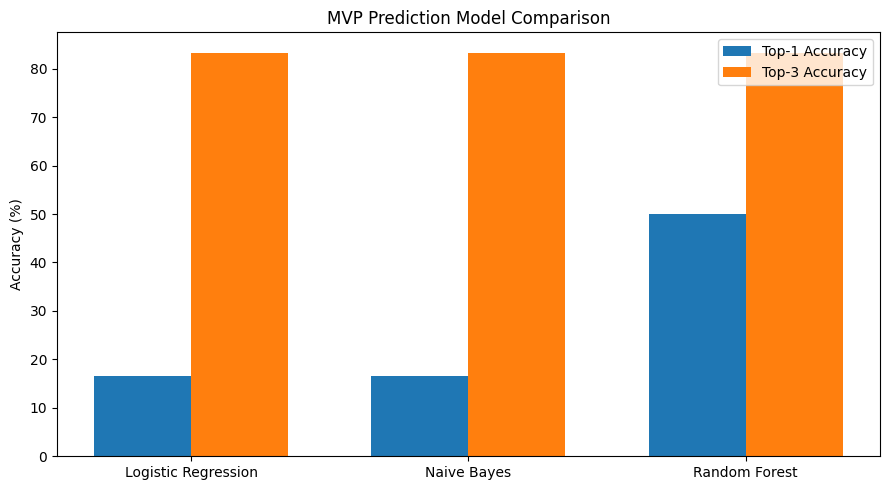

In [82]:
import matplotlib.pyplot as plt

models = model_summary["Model"]
top1 = model_summary["Top-1 Accuracy"] * 100
top3 = model_summary["Top-3 Accuracy"] * 100

x = range(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    [i - width/2 for i in x],
    top1,
    width,
    label="Top-1 Accuracy"
)

plt.bar(
    [i + width/2 for i in x],
    top3,
    width,
    label="Top-3 Accuracy"
)

plt.xticks(list(x), models)
plt.ylabel("Accuracy (%)")
plt.title("MVP Prediction Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()

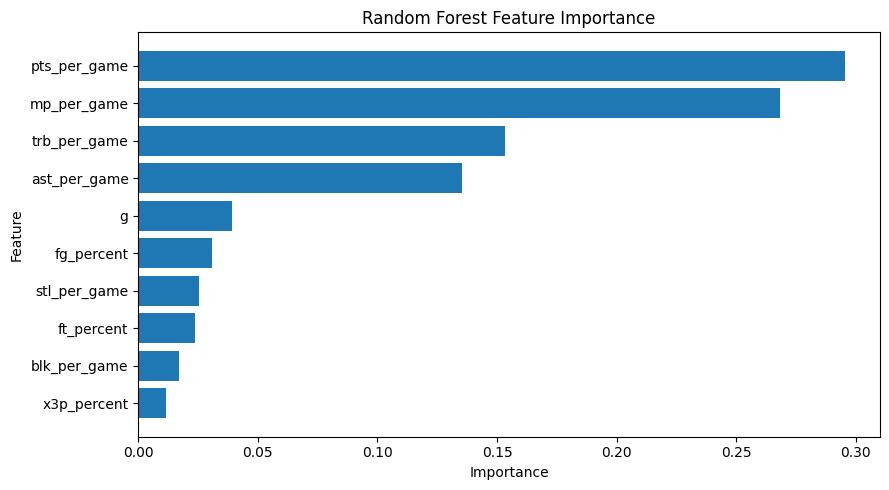

In [83]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [84]:
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 1.26.4
Pandas: 3.0.4


In [85]:
import os

print(os.path.exists("data/Player Award Shares.csv"))
print(os.path.exists("data/Player Per Game.csv"))

True
True


In [86]:
import pandas as pd

awards = pd.read_csv("data/Player Award Shares.csv")
stats = pd.read_csv("data/Player Per Game.csv")

print("Awards dataset:", awards.shape)
print("Player statistics dataset:", stats.shape)

Awards dataset: (3465, 10)
Player statistics dataset: (33339, 32)


In [87]:
import pandas as pd

In [88]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

print(feature_importance)

        Feature  Importance
9  pts_per_game    0.295326
1   mp_per_game    0.268339
5  trb_per_game    0.153110
6  ast_per_game    0.135359
0             g    0.039198
2    fg_percent    0.030931
7  stl_per_game    0.025326
4    ft_percent    0.023663
8  blk_per_game    0.017012
3   x3p_percent    0.011736


In [89]:
print("model_summary exists:", "model_summary" in globals())
print("feature_importance exists:", "feature_importance" in globals())
print("rf exists:", "rf" in globals())
print("features exists:", "features" in globals())

model_summary exists: True
feature_importance exists: True
rf exists: True
features exists: True


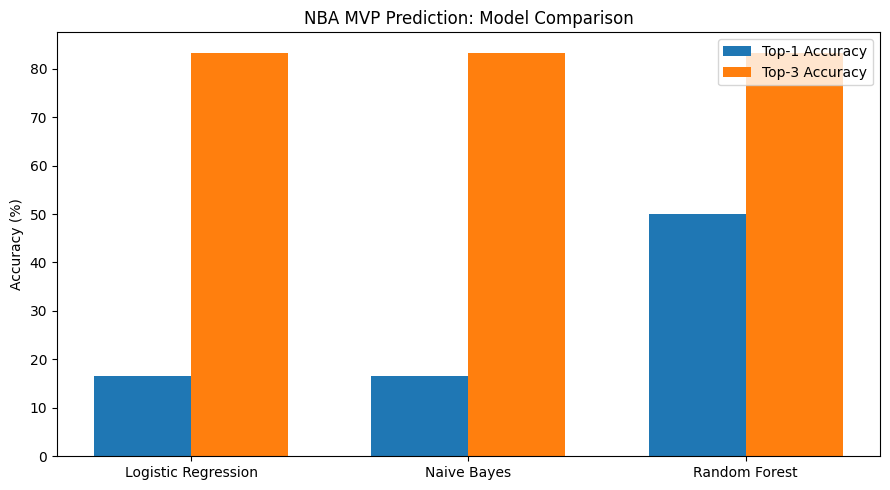

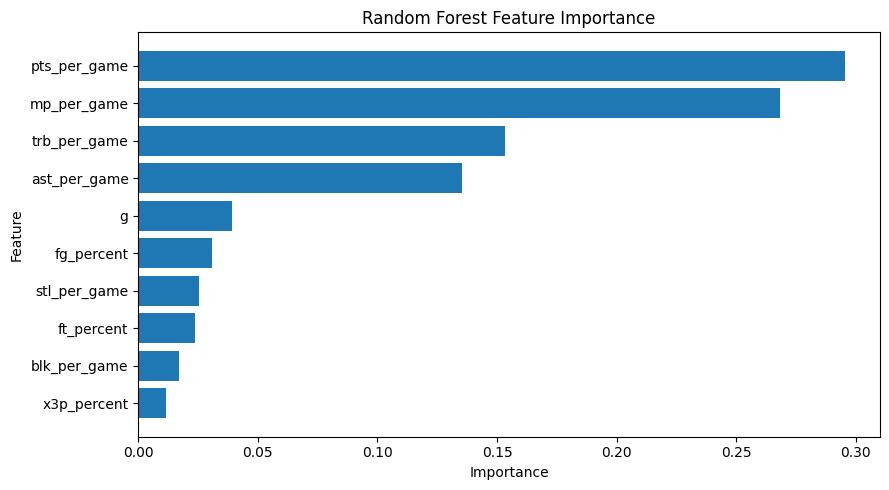

Both graphs saved successfully!


In [92]:
import os
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

# Model comparison graph
models = model_summary["Model"]
top1 = model_summary["Top-1 Accuracy"] * 100
top3 = model_summary["Top-3 Accuracy"] * 100

x = range(len(models))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar([i - width/2 for i in x], top1, width, label="Top-1 Accuracy")
plt.bar([i + width/2 for i in x], top3, width, label="Top-3 Accuracy")
plt.xticks(list(x), models)
plt.ylabel("Accuracy (%)")
plt.title("NBA MVP Prediction: Model Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("results/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Feature importance graph
plt.figure(figsize=(9, 5))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("results/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

print("Both graphs saved successfully!")

In [91]:
import os

print(os.listdir("results"))

['feature_importance.png', 'model_comparison.png']
